# 8. Model Training with ThreeWToolkit

## Learning Goals

By the end of this notebook, you should be able to:

- split event instances into training, validation, and test sets without leakage;
- build a reproducible transformation pipeline;
- train classical and neural models through the toolkit's trainer API;
- evaluate predictions with accuracy and a normalized confusion matrix; and
- identify parameters to change for a larger experiment.

This notebook turns prepared 3W time series into machine-learning samples and trains two classifiers with the `ThreeWToolkit`.


## 📋 Table of Contents

1. [Select a reproducible dataset subset](#1-select-a-reproducible-dataset-subset)
2. [Create train, validation, and test partitions](#2-create-train-validation-and-test-partitions)
3. [Build the data transformation pipeline](#3-build-the-data-transformation-pipeline)
4. [Example A — train a scikit-learn Random Forest](#4-example-a-train-a-scikit-learn-random-forest)
5. [Example B — train a PyTorch MLP](#5-example-b-train-a-pytorch-mlp)
6. [Comparing the experiments](#6-comparing-the-experiments)
7. [Next Steps](#7-next-steps)


In [47]:
import matplotlib.pyplot as plt
from ThreeWToolkit.assessment import (
    AssessmentVisualizationConfig,
    ModelAssessmentConfig,
)
from ThreeWToolkit.dataset import ParquetDatasetConfig, TransformConfig
from ThreeWToolkit.feature_extraction import (
    ConcatFeatureAdapterConfig,
    SequentialFeatureAdapterConfig,
    StatisticalConfig,
    WindowingConfig,
)
from ThreeWToolkit.preprocessing import (
    CleanSignalsConfig,
    FillLabelsConfig,
    ImputeMissingConfig,
    NormalizeConfig,
    RemapClassConfig,
    SequentialPreprocessingAdapterConfig,
)
from ThreeWToolkit.utils import TrainTestSplitter

RANDOM_SEED = 2026
DATASET_PATH = "../../dataset"

## 1. Select a reproducible dataset subset

An instance is one complete event time series. We split **instances**, rather than individual rows, so windows from the same well event cannot appear in both training and test data.

For a quick classroom run, the next cell selects a bounded number of simulated instances from event classes 1–5. Set `MAX_INSTANCES = None` to use every matching instance. The event type and class filters are part of `ParquetDatasetConfig`, so loading remains inside the toolkit instead of using ad-hoc Parquet loops.


In [ ]:
SELECTED_CLASSES = [1, 2, 3, 4, 5]

dataset = ParquetDatasetConfig(
    path=DATASET_PATH,
    split="list",
    target_class=SELECTED_CLASSES,
    event_type=["simulated"],
).build()

print(f"Loaded {len(dataset)} event instances")
print(f"Classes: {SELECTED_CLASSES}")

2026-10-16 14:30:08,241 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ../../dataset
2026-10-16 14:30:08,243 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-10-16 14:30:08,244 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


Loaded 643 event instances
Classes: [1, 2, 3, 4, 5]
First instance: {'file_name': PosixPath('1/SIMULATED_00001.parquet'), 'event_class': 1, 'event_type': 'simulated'}


### Inspect one event before training

The toolkit represents an event as `DatasetOutputs`: a signal `DataFrame`, an optional label `Series`, and metadata. Looking at one object makes the later transformations easier to understand.

In [49]:
example = dataset[0]
print("Signal shape:", example.signal.shape)
print("Signal columns:", list(example.signal.columns))
print("Label values:", example.label.dropna().unique() if example.label is not None else None)
display(example.signal.head())

Signal shape: (45599, 28)
Signal columns: ['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL', 'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT', 'state']
Label values: <IntegerArray>
[0, 101, 1]
Length: 3, dtype: Int16


,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,...,P-PDG,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,state
timestamp,,,,,,,,,,,,,,,,,,,,,
2018-10-06 03:57:02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252041e+07,NaN,1.306863e+07,NaN,NaN,70.334018,NaN,NaN,96.93275,0
2018-10-06 03:57:03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252043e+07,NaN,1.306865e+07,NaN,NaN,70.334248,NaN,NaN,96.93279,0
2018-10-06 03:57:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252044e+07,NaN,1.306864e+07,NaN,NaN,70.334488,NaN,NaN,96.93283,0
2018-10-06 03:57:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252042e+07,NaN,1.306860e+07,NaN,NaN,70.334728,NaN,NaN,96.93287,0
2018-10-06 03:57:06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252039e+07,NaN,1.306856e+07,NaN,NaN,70.334958,NaN,NaN,96.93290,0


---


## 2. Create train, validation, and test partitions

The first split reserves 20% of instances for final testing. A second split divides the remaining 80% into training and validation sets. We stratify by `event_class` and `event_type`, which keeps the event composition similar across partitions when enough instances are available.

The test set is not inspected while choosing preprocessing or model hyperparameters. It is used once at the end as an estimate of performance on unseen instances.


In [50]:
splitter = TrainTestSplitter(
    size_training=0.8,
    size_test=0.2,
    stratify_by=["event_class", "event_type"],
    random_state=RANDOM_SEED,
)
train_val, test = splitter.split_data(dataset)

train_splitter = TrainTestSplitter(
    size_training=0.75,
    size_test=0.25,
    stratify_by=["event_class", "event_type"],
    random_state=RANDOM_SEED,
)
train, validation = train_splitter.split_data(train_val)

print(f"Training instances:   {len(train):>4}")
print(f"Validation instances: {len(validation):>4}")
print(f"Test instances:       {len(test):>4}")

Training instances:    385
Validation instances:  129
Test instances:        129


---


## 3. Build the data transformation pipeline

Raw event signals are not yet in the two-dimensional format expected by most classifiers. The transform below performs the following operations:

1. **CleanSignals** removes unusable signal columns.
2. **ImputeMissing** fills missing sensor values.
3. **Normalize** puts variables on comparable scales.
4. **FillLabels** makes sure every time step has a usable label.
5. **RemapClass** maps labels to consecutive class IDs for model training.
6. **Windowing** converts each event into fixed-length windows.
7. **StatisticalFeatures** summarizes each window using mean, standard deviation, quantiles, and other statistics.

The fitted transform is shared by all three partitions. Calling `fit(train)` before `transform(...)` is the important step that prevents information from validation or test data leaking into training.


In [51]:
WINDOW_SIZE = 128

transform = TransformConfig(
    pre_processing=SequentialPreprocessingAdapterConfig(
        steps=[
            CleanSignalsConfig(),
            ImputeMissingConfig(),
            NormalizeConfig(),
            FillLabelsConfig(),
            RemapClassConfig(),
        ]
    ),
    feature_extraction=SequentialFeatureAdapterConfig(
        steps=[
            WindowingConfig(window_size=WINDOW_SIZE),
            ConcatFeatureAdapterConfig(steps=[StatisticalConfig()]),
        ]
    ),
).build()

transform.fit(train)
train_features = transform.transform(train)
validation_features = transform.transform(validation)
test_features = transform.transform(test)

print("Training feature matrix:", train_features[0].signal.shape)
print("Validation feature matrix:", validation_features[0].signal.shape)
print("Test feature matrix:", test_features[0].signal.shape)
print("Number of classes:", transform.num_classes)

Training feature matrix: (229, 170)
Validation feature matrix: (694, 170)
Test feature matrix: (229, 170)
Number of classes: 8


Each transformed event can contain several windows, and each window is one training sample. The feature columns are named with the source variable and statistic, for example `P-PDG_mean` or `T-TPT_std`.

In [52]:
display(train_features[2].signal.iloc[10:20, 8:18])
print("Transformed labels:", train_features[2].label.unique())

,mean_ESTADO-XO,mean_P-JUS-CKP,mean_P-MON-CKP,mean_P-PDG,mean_P-TPT,mean_T-JUS-CKP,mean_T-MON-CKP,mean_T-TPT,mean_state,std_ESTADO-DHSV
window,,,,,,,,,,
10,0.0,1.415623,-0.446308,0.710721,1.129111,0.511993,1.119193,0.639642,0.0,0.0
11,0.0,1.415276,-0.446519,0.693573,1.112312,0.509217,1.118188,0.639119,0.0,0.0
12,0.0,1.414781,-0.446820,0.675068,1.093890,0.504394,1.116452,0.638568,0.0,0.0
13,0.0,1.413920,-0.447332,0.655246,1.073902,0.498583,1.114324,0.637989,0.0,0.0
14,0.0,1.412723,-0.448034,0.634610,1.053281,0.492682,1.112118,0.637411,0.0,0.0
15,0.0,1.411192,-0.448928,0.612875,1.031563,0.487183,1.110004,0.636807,0.0,0.0
16,0.0,1.409422,-0.450002,0.589932,1.008626,0.482384,1.108072,0.636167,0.0,0.0
17,0.0,1.407334,-0.451282,0.565711,0.984402,0.478489,1.106405,0.635488,0.0,0.0
18,0.0,1.405076,-0.452664,0.539866,0.958435,0.475235,1.104947,0.634756,0.0,0.0


Transformed labels: [0 7 4]


---


## 4. Example A — train a scikit-learn Random Forest

A Random Forest is a useful baseline for a presentation because it is fast, robust, and easy to compare with other tabular classifiers. `SklearnModelsConfig` wraps the native scikit-learn estimator, while `SklearnTrainerConfig` adapts it to the toolkit's common trainer interface.


In [53]:
from sklearn.ensemble import RandomForestClassifier
from ThreeWToolkit.models import SklearnModelsConfig
from ThreeWToolkit.trainer import SklearnTrainerConfig

random_forest = SklearnTrainerConfig(
    config_model=SklearnModelsConfig(
        model_type=RandomForestClassifier,
        model_params={
            "n_estimators": 80,
            "max_depth": 12,
            "random_state": RANDOM_SEED,
        },
    ),
    seed=RANDOM_SEED,
    use_class_weights=True,
).build()

rf_training = random_forest.train(
    train_dataset=train_features,
    val_dataset=validation_features,
)
rf_predictions = random_forest.predict(test_features)

2026-10-16 14:31:36,513 | INFO | ThreeWToolkit.core.base_trainer | Initialized SklearnTrainer with seed=2026
2026-10-16 14:31:36,516 | INFO | ThreeWToolkit.trainer.sklearn_trainer | SklearnTrainer initialized | model=RandomForestClassifier | n_jobs=16
2026-10-16 14:31:36,518 | INFO | ThreeWToolkit.core.base_trainer | Starting training | train_size=385 | val_size=129
2026-10-16 14:31:36,799 | INFO | ThreeWToolkit.core.base_trainer | Dataset validation passed
2026-10-16 14:31:36,800 | INFO | ThreeWToolkit.core.base_trainer | Preparing training data...
2026-10-16 14:31:36,801 | INFO | ThreeWToolkit.trainer.sklearn_trainer | Converting dataset to arrays (size=385)
2026-10-16 14:32:29,595 | INFO | ThreeWToolkit.trainer.sklearn_trainer | Created arrays | X.shape=(121998, 170) | y.shape=(121998,)
2026-10-16 14:32:29,599 | INFO | ThreeWToolkit.core.base_trainer | Preparing validation data...
2026-10-16 14:32:29,600 | INFO | ThreeWToolkit.trainer.sklearn_trainer | Converting dataset to arrays (

### Evaluate the Random Forest

`ModelAssessment` keeps evaluation separate from training. This makes it possible to reuse the same metrics and visualizations for both model families.

In [54]:
assessment = ModelAssessmentConfig(metrics=["accuracy"]).build()
rf_assessment = assessment.evaluate(
    training_results=rf_training,
    predictions=rf_predictions,
)
print(rf_assessment)

2026-10-16 14:32:57,395 | INFO | ThreeWToolkit.assessment.model_assess | Results exported to /home/eduardo/3W/toolkit/output/exp_20261016_1432
2026-10-16 14:32:57,396 | INFO | ThreeWToolkit.assessment.model_assess | Model Assessment Summary
Model: SklearnModels
Task Type: classification
Timestamp: 20261016_1432

Metrics:
  accuracy: 0.8814

Training History:
  Final train_loss: 0.9777
  Final val_loss: 0.8983


model=<ThreeWToolkit.models.sklearn_models.SklearnModels object at 0x75ec2c3b1e50> task_type=<TaskTypeEnum.CLASSIFICATION: 'classification'> timestamp='20261016_1432' true_values=array([0, 0, 0, ..., 4, 4, 4], shape=(39988,)) predictions=array([0, 4, 4, ..., 4, 4, 4], shape=(39988,)) metrics={'accuracy': 0.8814144243272982} training_history=TrainingHistory(train_loss=[0.9776881588222758], val_loss=[0.8982850384387936]) experiment_dir='/home/eduardo/3W/toolkit/output/exp_20261016_1432'


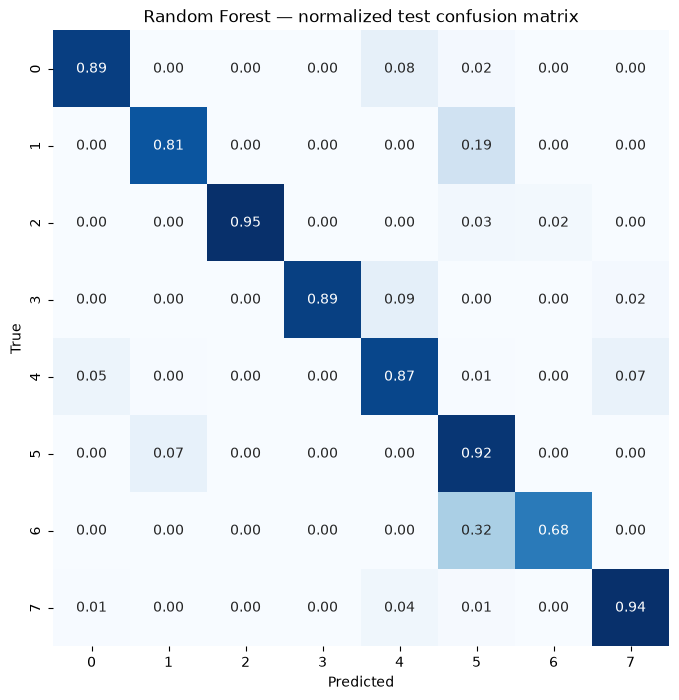

In [55]:
rf_plotter = AssessmentVisualizationConfig().build()
rf_plotter.plot_confusion_matrix(
    y_true=rf_predictions.y_true,
    y_pred=rf_predictions.y_pred,
    normalize=True,
    title="Random Forest — normalized test confusion matrix",
);

Read a normalized confusion matrix row by row: each row is a true class and each column is a predicted class. A strong diagonal means that the model recognizes that class; off-diagonal values show which events are confused. In a real study, inspect these errors together with the time series and the transient-label convention.

---


## 5. Example B — train a PyTorch MLP

The same transformed feature datasets can be passed to a neural model. `MLPConfig` describes the network, and `TorchTrainerConfig` supplies the optimization loop. The output size must equal `transform.num_classes`, not the largest original class number, because `RemapClass` creates consecutive labels. This configuration uses moderate capacity, a smaller learning rate, GELU activations, and a validation-oriented epoch budget to reduce overfitting.


In [56]:
from ThreeWToolkit.models import MLPConfig
from ThreeWToolkit.trainer import TorchTrainerConfig
from torch import nn

mlp = TorchTrainerConfig(
    config_model=MLPConfig(
        hidden_sizes=(64, 32),
        activation_function=nn.GELU(),
        output_size=transform.num_classes,
    ),
    seed=RANDOM_SEED,
    use_class_weights=True,
    class_weight_strategy="balanced",
    learning_rate=0.0005,
    batch_size=32,
    epochs=25,
    device="cpu"
).build()

mlp_training = mlp.train(
    train_dataset=train_features,
    val_dataset=validation_features,
)
mlp_predictions = mlp.predict(test_features)

2026-10-16 14:32:58,067 | INFO | ThreeWToolkit.core.base_trainer | Initialized TorchTrainer with seed=2026
2026-10-16 14:32:58,069 | INFO | ThreeWToolkit.trainer.torch_trainer | TorchTrainer initialized | device=cpu | epochs=25 | batch_size=32
2026-10-16 14:32:58,071 | INFO | ThreeWToolkit.core.base_trainer | Starting training | train_size=385 | val_size=129
2026-10-16 14:32:58,434 | INFO | ThreeWToolkit.core.base_trainer | Dataset validation passed
2026-10-16 14:32:58,436 | INFO | ThreeWToolkit.core.base_trainer | Preparing training data...
2026-10-16 14:32:58,437 | INFO | ThreeWToolkit.trainer.torch_trainer | Converting dataset to DataLoader (size=385)
2026-10-16 14:33:33,062 | INFO | ThreeWToolkit.trainer.torch_trainer | Created DataLoader | batches=3813
2026-10-16 14:33:33,064 | INFO | ThreeWToolkit.core.base_trainer | Preparing validation data...
2026-10-16 14:33:33,065 | INFO | ThreeWToolkit.trainer.torch_trainer | Converting dataset to DataLoader (size=129)
2026-10-16 14:33:44,1

Training:   0%|          | 0/25 [00:00<?, ?epoch/s]

2026-10-16 14:37:30,694 | INFO | ThreeWToolkit.core.base_trainer | Training completed successfully
2026-10-16 14:37:30,704 | INFO | ThreeWToolkit.trainer.torch_trainer | Converting dataset to DataLoader (size=129)
2026-10-16 14:37:42,664 | INFO | ThreeWToolkit.trainer.torch_trainer | Created DataLoader | batches=1250


Unlike the scikit-learn trainer, the MLP records one training and validation loss per epoch. Plotting the history helps diagnose underfitting, overfitting, or an unsuitable learning rate.

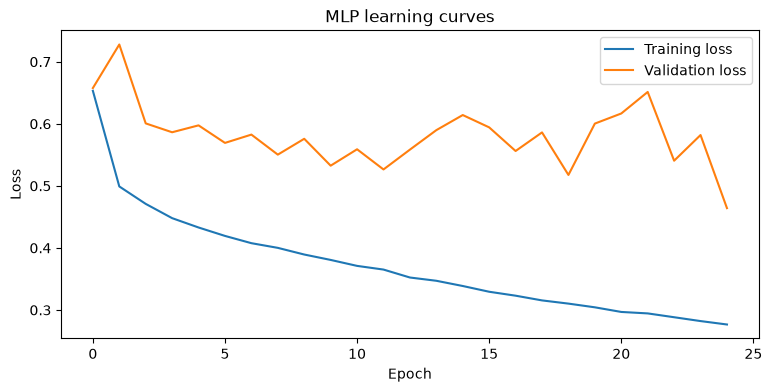

In [57]:
history = mlp_training.history
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history.train_loss, label="Training loss")
ax.plot(history.val_loss, label="Validation loss")
ax.set(title="MLP learning curves", xlabel="Epoch", ylabel="Loss")
ax.legend();

2026-10-16 14:37:43,557 | INFO | ThreeWToolkit.assessment.model_assess | Results exported to /home/eduardo/3W/toolkit/output/exp_20261016_1437
2026-10-16 14:37:43,559 | INFO | ThreeWToolkit.assessment.model_assess | Model Assessment Summary
Model: MLP
Task Type: classification
Timestamp: 20261016_1437

Metrics:
  accuracy: 0.8545

Training History:
  Final train_loss: 0.2766
  Final val_loss: 0.4641


model=MLP(
  (activation_func): GELU(approximate='none')
  (model): Sequential(
    (0): Linear(in_features=170, out_features=64, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=32, out_features=8, bias=True)
  )
) task_type=<TaskTypeEnum.CLASSIFICATION: 'classification'> timestamp='20261016_1437' true_values=array([0, 0, 0, ..., 4, 4, 4], shape=(39988,)) predictions=array([4, 4, 4, ..., 4, 4, 4], shape=(39988,)) metrics={'accuracy': 0.854481344403321} training_history=TrainingHistory(train_loss=[0.6531519748577289, 0.4990573458758483, 0.4709646011906176, 0.44797530342377045, 0.43291662346474963, 0.41935665470027966, 0.4076442091869629, 0.4001053626578982, 0.38937212896982487, 0.38066665522085924, 0.3710612992746543, 0.3651304652026803, 0.3523258890603944, 0.34707098238613704, 0.3386502258876256, 0.32937421778267273, 0.3230468776148353, 0.31544132264017855, 0.310272217

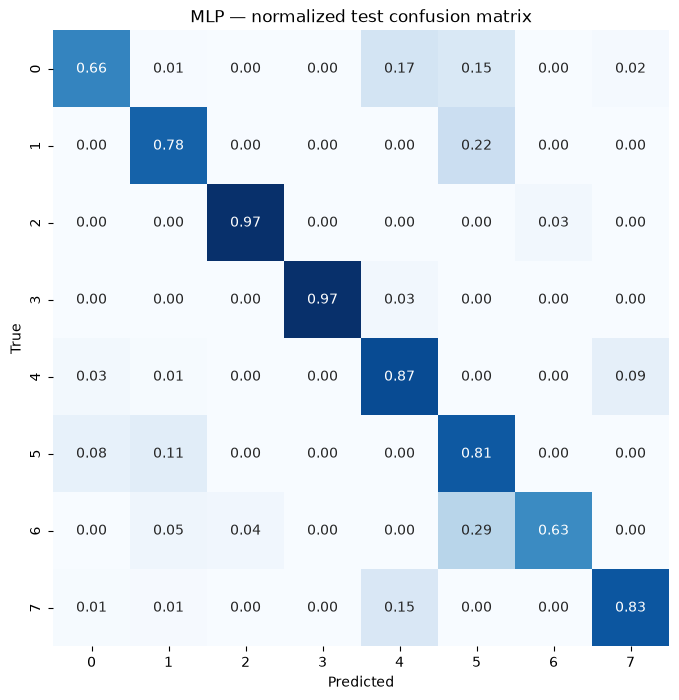

In [58]:
mlp_assessment = assessment.evaluate(
    training_results=mlp_training,
    predictions=mlp_predictions,
)
print(mlp_assessment)

mlp_plotter = AssessmentVisualizationConfig().build()
mlp_plotter.plot_confusion_matrix(
    y_true=mlp_predictions.y_true,
    y_pred=mlp_predictions.y_pred,
    normalize=True,
    title="MLP — normalized test confusion matrix",
);

---


## 6. Comparing the experiments

Accuracy is convenient for a first comparison, but it should not be the only number reported when classes are imbalanced. Add balanced accuracy, precision, recall, F1, or domain-specific metrics in notebook 9. Also report the exact split, random seed, window size, feature set, and model parameters so another person can reproduce the result.


In [59]:
import pandas as pd

comparison = pd.DataFrame(
    {
        "model": ["Random Forest", "MLP"],
        "test_accuracy": [
            rf_assessment.metrics["accuracy"],
            mlp_assessment.metrics["accuracy"],
        ],
    }
)
display(comparison)

,model,test_accuracy
0,Random Forest,0.881414
1,MLP,0.854481


---


## 7. Next Steps

You have trained and compared two model families using a reproducible event-level split and a shared fitted transformation.

### What's Next?

- **Metrics and Evaluation**: Apply a broader set of metrics and assessment visualizations in [Notebook 9: Metrics and Evaluation](9_metrics_and_evaluation.ipynb)
- **Report Generation**: Package model results into an HTML report in [Notebook 10: Generating Reports](10_generating_reports.ipynb)
